# 03 · TACE first vs systemic first

Pairwise comparison of the two sequential strategies in stage III-IV patients: unadjusted,
PSM-matched and IPTW-weighted Kaplan-Meier curves and Cox models (Figure 3), stage-combination
subgroups, and exploratory analyses of the interval between treatments.

## Load data

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lifelines import CoxPHFitter
from lifelines.statistics import logrank_test
from sklearn.preprocessing import SplineTransformer

from hcc_tace import config
from hcc_tace.cohort import pairwise_cohort
from hcc_tace.plotting import DEFAULT, plot_iptw_diagnostics, plot_km_by_category
from hcc_tace.survival import best_logrank_cutpoint, survival_analysis, weighted_cox_hr
from hcc_tace.weighting import perform_iptw

config.setup_notebook()
covariates = config.COVARIATES

# Plot settings for this comparison
TACE_SYS = dict(
    groups=['TACE First', 'Systemic First'],
    colors=[config.COLORS['tace'], config.COLORS['systemic']],
    style=replace(DEFAULT, annot_offsets=(-0.075, 0.075)),
)

df = pd.read_csv(config.ANALYSIS_READY)
df.shape

(1858, 357)

### Filter out same day and early stage

In [2]:
df = df[df['sequence_group'].isin([0, 1])]
df = df[df['COMBINED_STAGE_GROUP'].isin([3, 4])]

In [3]:
df['sequence_group'].value_counts(), df.shape

(sequence_group
 0    930
 1    205
 Name: count, dtype: int64,
 (1135, 357))

## Unweighted Survival Analysis

<lifelines.CoxPHFitter: fitted with 1135 total observations, 285 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1135
number of events observed = 850
   partial log-likelihood = -5384.50
         time fit was run = 2026-11-01 22:28:22 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.19      0.82      0.09           -0.38           -0.01                0.69                0.99

                cmp to     z    p  -log2(p)
covariate                                  
sequence_group    0.00 -2.08 0.04      4.74
---
Concordance = 0.52
Partial AIC = 10770.99
log-likelihood ratio test = 4.53 on 1 df
-log2(p) of ll-ratio test = 4.91


Time: 36 months
TACE First: 21.3% (18.4% – 24.1%)
Systemic First: 28.9% (20.6% – 35.2%)

Time: 60 months
TACE First: 14.4% (11.6% – 17.5%)
Systemic First: 14.0% (5.9% – 25.6%)


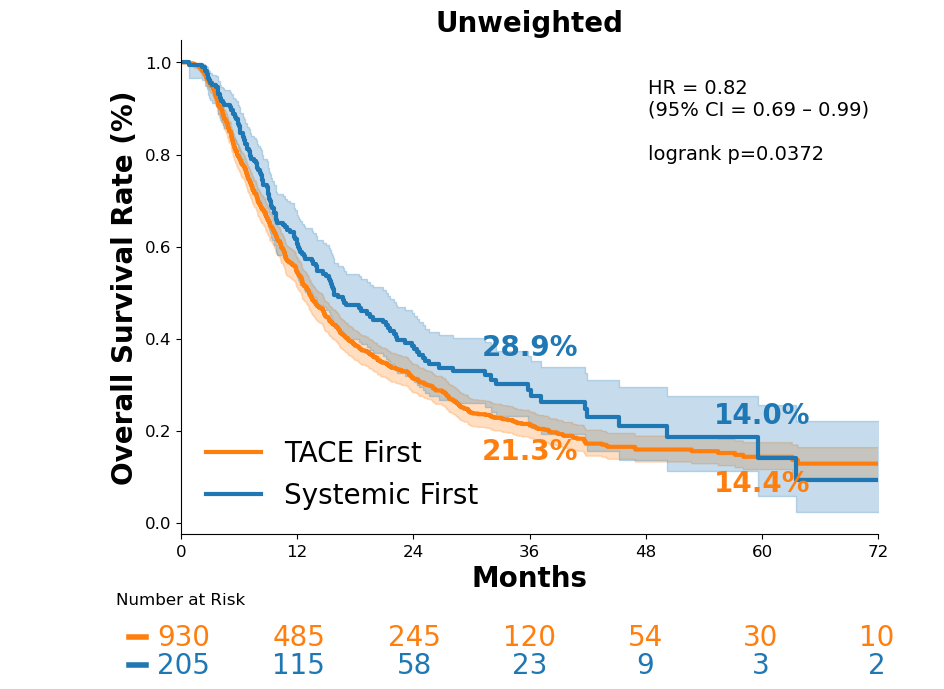

In [4]:
survival_analysis(df, config.TIME_GRID, **TACE_SYS);  # , file_name='tace_sys_unweighted'

<lifelines.CoxPHFitter: fitted with 797 total observations, 220 right-censored observations>
             duration col = 'time'
                event col = 'event'
                   strata = subclass
      baseline estimation = breslow
   number of observations = 797
number of events observed = 577
   partial log-likelihood = -550.83
         time fit was run = 2026-11-01 22:28:23 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.17      0.84      0.12           -0.40            0.05                0.67                1.06

                cmp to     z    p  -log2(p)
covariate                                  
sequence_group    0.00 -1.49 0.14      2.88
---
Concordance = 0.52
Partial AIC = 1103.65
log-likelihood ratio test = 2.27 on 1 df
-log2(p) of ll-ratio test = 2.93


Time: 36 months
TACE First: 19.6% (16.0% – 23.4%)
Systemic First: 28.4% (21.3% – 35.9%)

Time: 60 months
TACE First: 14.0% (10.2% – 18.5%)
Systemic First: 14.4% (6.0% – 26.2%)


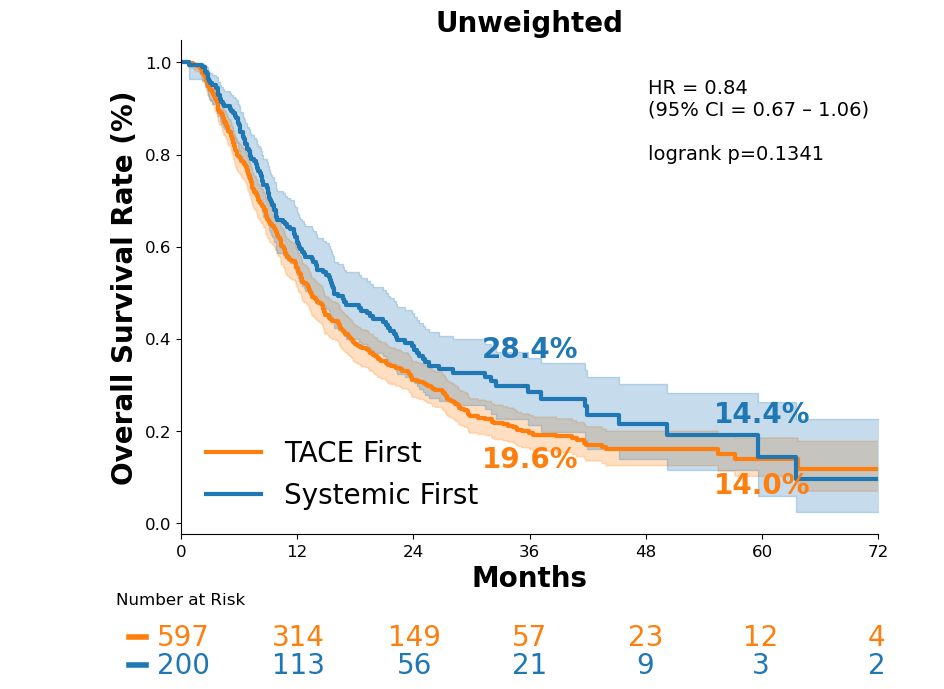

In [5]:
df_matched = pd.read_csv(config.PROCESSED_DIR / 'matched_tace_sys.csv')
survival_analysis(df_matched, config.TIME_GRID, strata='subclass', **TACE_SYS);  # , file_name='tace_sys_psm'

In [6]:
cph = CoxPHFitter()
cph.fit(df_matched[['time', 'event', 'sequence_group', 'subclass']], duration_col='time', event_col='event', strata='subclass')
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 797 total observations, 220 right-censored observations>
             duration col = 'time'
                event col = 'event'
                   strata = subclass
      baseline estimation = breslow
   number of observations = 797
number of events observed = 577
   partial log-likelihood = -550.83
         time fit was run = 2026-11-01 22:28:24 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.17      0.84      0.12           -0.40            0.05                0.67                1.06

                cmp to     z    p  -log2(p)
covariate                                  
sequence_group    0.00 -1.49 0.14      2.88
---
Concordance = 0.52
Partial AIC = 1103.65
log-likelihood ratio test = 2.27 on 1 df
-log2(p) of ll-ratio test = 2.93

## IPTW

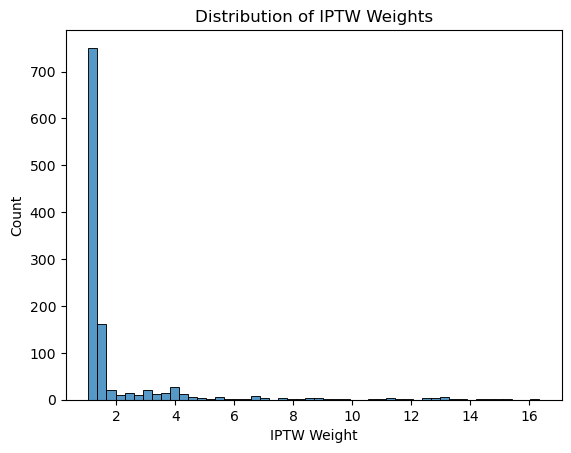

In [7]:
df = perform_iptw(df, covariates)

sns.histplot(df['iptw_weight'], bins=50)
plt.title("Distribution of IPTW Weights")
plt.xlabel("IPTW Weight")
plt.ylabel("Count")
plt.show()

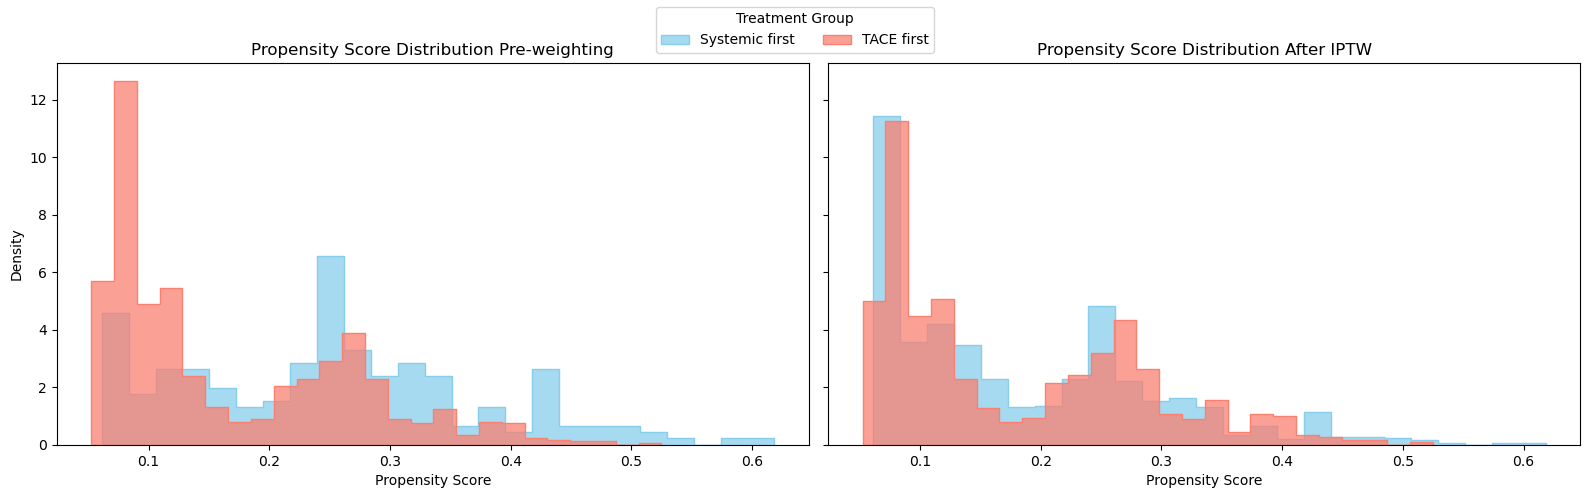

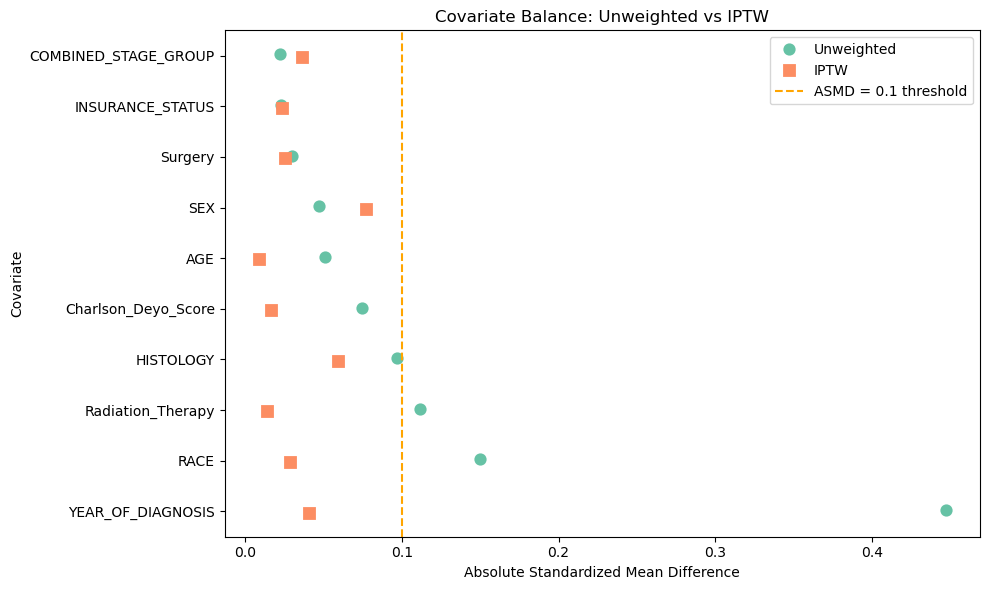

In [8]:
asmd_df = plot_iptw_diagnostics(df, ['TACE first', 'Systemic first'])  # , file_name='tace_sys'

## IPTW Weighted Survival Analysis

<lifelines.CoxPHFitter: fitted with 2246.04 total observations, 616.269 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2246.04
number of events observed = 1629.77
   partial log-likelihood = -11453.68
         time fit was run = 2026-11-01 22:28:27 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.21      0.81      0.05           -0.30           -0.11                0.74                0.90

                cmp to     z      p  -log2(p)
covariate                                    
sequence_group    0.00 -4.16 <0.005     14.95
---
Concordance = 0.52
Partial AIC = 22909.35
log-likelihood ratio test = 17.36 on 1 df
-log2(p) of ll-ratio test = 14.98


Time: 36 months
TACE First: 21.3% (18.6% – 23.9%)
Systemic First: 30.3% (27.0% – 32.9%)

Time: 60 months
TACE First: 14.4% (11.8% – 17.2%)
Systemic First: 18.3% (14.9% – 21.9%)


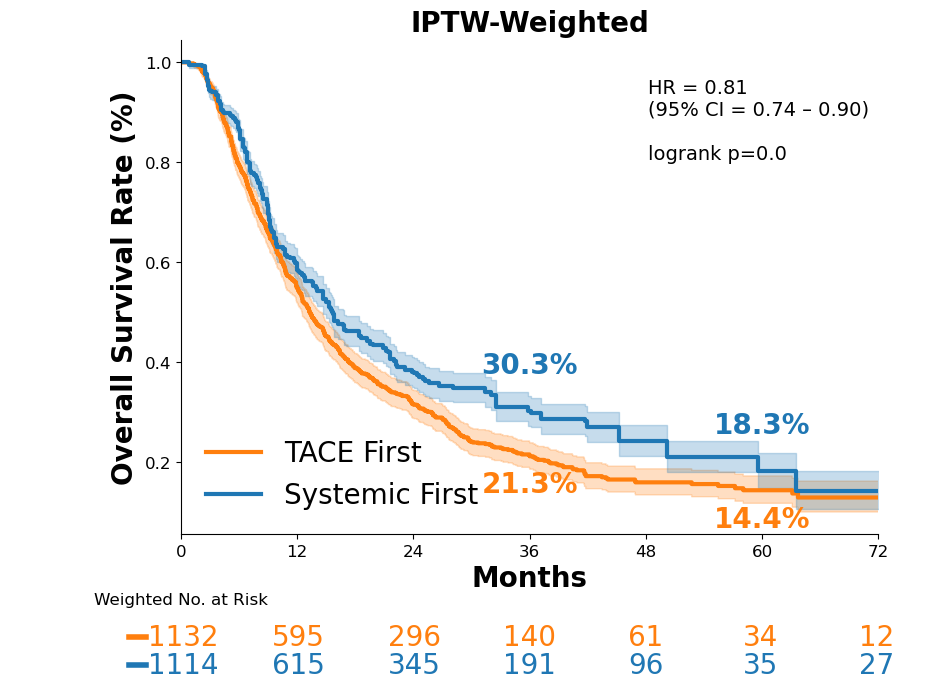

In [9]:
survival_analysis(df, config.TIME_GRID, weight_col='iptw_weight', **TACE_SYS);  # , file_name='tace_sys_iptw'

## TACE first vs. Systemic first in different combinations of stages

In [10]:
combinations = [
    [1], [2], [3], [4],
    [1, 2], [2, 3], [3, 4],
    [1, 2, 3], [2, 3, 4]
]

df_all = pd.read_csv(config.ANALYSIS_READY)
rows = []
for combo in combinations:
    df_combo = pairwise_cohort(df_all, config.TACE_FIRST, config.SYSTEMIC_FIRST)
    df_combo = df_combo[df_combo['COMBINED_STAGE_GROUP'].isin(combo)].copy()
    # Stage is constant within a single-stage subgroup, so drop it from the PS model
    covs = [c for c in covariates if c != 'COMBINED_STAGE_GROUP'] if len(combo) == 1 else covariates
    df_combo = perform_iptw(df_combo, covariates=covs)
    rows.append({'Stage Combination': ' + '.join(map(str, combo)), **weighted_cox_hr(df_combo)})

df_results = pd.DataFrame(rows)

In [11]:
df_results

,Stage Combination,HR,CI Low,CI High,p-value,n
0,1,0.711177,0.501795,1.007927,0.0554,136
1,2,0.955567,0.749335,1.218557,0.7141,225
2,3,0.782908,0.679608,0.901910,0.0007,571
3,4,0.798313,0.695124,0.916820,0.0014,564
4,1 + 2,0.947095,0.780069,1.149883,0.5829,361
5,2 + 3,0.858711,0.760535,0.969560,0.0139,796
6,3 + 4,0.813090,0.737590,0.896319,0.0000,1135
7,1 + 2 + 3,0.865054,0.772251,0.969009,0.0123,932
8,2 + 3 + 4,0.857621,0.783950,0.938216,0.0008,1360


## Spacing analysis - Systemic first

In [12]:
df_sys = df[(df['sequence_group'].isin([1,2])) & df['COMBINED_STAGE_GROUP'].isin([3,4])].copy()
df_sys = df_sys[df_sys['DX_IMMUNO_STARTED_DAYS'] <= df_sys['DX_CHEMO_STARTED_DAYS']]

In [13]:
df_sys.shape

(205, 359)

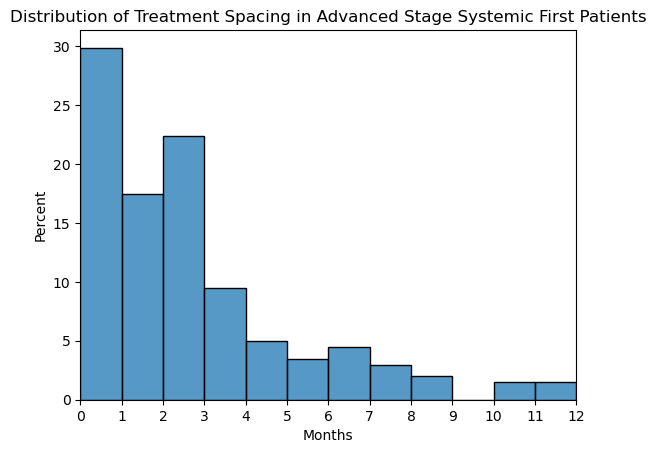

In [14]:
df_sys['treatment_spacing'] =  abs(df_sys['DX_CHEMO_STARTED_DAYS'] - df_sys['DX_IMMUNO_STARTED_DAYS'])
#df_sys = df_sys[df_sys['treatment_spacing'] <= 90] 

df_sys['treatment_spacing_months'] = df_sys['treatment_spacing'] / 30.44  # Convert to months

bin_edges = np.linspace(0, 12, 13)  # Create 12 bins from 0 to 12 months
sns.histplot(df_sys['treatment_spacing_months'], bins=bin_edges, stat="percent")
plt.title("Distribution of Treatment Spacing in Advanced Stage Systemic First Patients")
plt.xlabel("Months")
plt.xlim(0, 12)
plt.xticks(bin_edges)
# plt.savefig("treatment_spacing_distribution.pdf", format='pdf', bbox_inches='tight')
plt.show()

### 7,14,28

In [15]:
df_sys['spacing_week'] = pd.cut(
    df_sys['treatment_spacing'],
    bins=[-1, 7, 14, 28, np.inf],
    labels=['≤7 days', '8–14 days', '15–28 days', '>28 days']
)

# df_sys['spacing_week'] = pd.Categorical(
#     df_sys['spacing_week'], 
#     categories=['≤7 days', '15–28 days', '8–14 days', '>28 days'],
#     ordered=True
# )

In [16]:
cph_7 = CoxPHFitter()
df_dummies1 = pd.get_dummies(df_sys, columns=['spacing_week'], drop_first=True)
# cph_7.fit(
#     df_dummies1[['time', 'event'] + list(df_dummies1.columns[df_dummies1.columns.str.startswith('spacing_week_')])], 
#     duration_col='time', 
#     event_col='event')
# cph_7.print_summary()

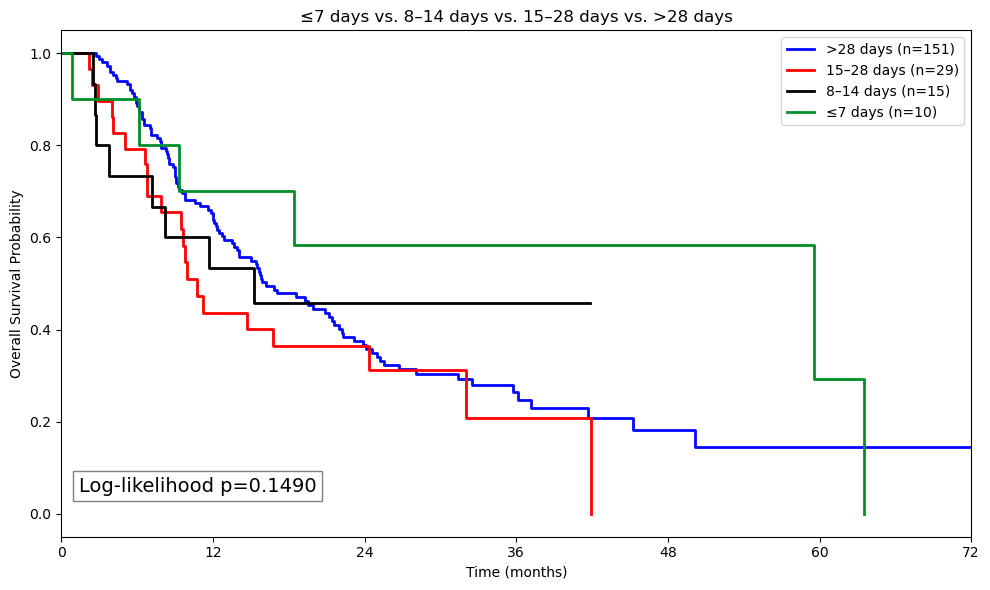

In [17]:
plot_km_by_category(df_sys, 'spacing_week', "≤7 days vs. 8–14 days vs. 15–28 days vs. >28 days", 0.149)

### 30, 90

In [18]:
df_sys['spacing_3090'] = pd.cut(
    df_sys['treatment_spacing'],
    bins=[-1, 30, 90, np.inf],
    labels=['≤30 days', '31–90 days', '>90 days']
)

df_sys['spacing_3090'] = pd.Categorical(
    df_sys['spacing_3090'],
    categories=['>90 days', '31–90 days', '≤30 days'],  # Reorder categories
    ordered=True
)

In [19]:
# cph_3090 = CoxPHFitter()
# df_dummies2 = pd.get_dummies(df_sys, columns=['spacing_3090'], drop_first=True)
# cph_3090.fit(
#     df_dummies2[['time', 'event'] + list(df_dummies2.columns[df_dummies2.columns.str.startswith('spacing_3090_')])], 
#     duration_col='time', 
#     event_col='event')
# cph_3090.print_summary()

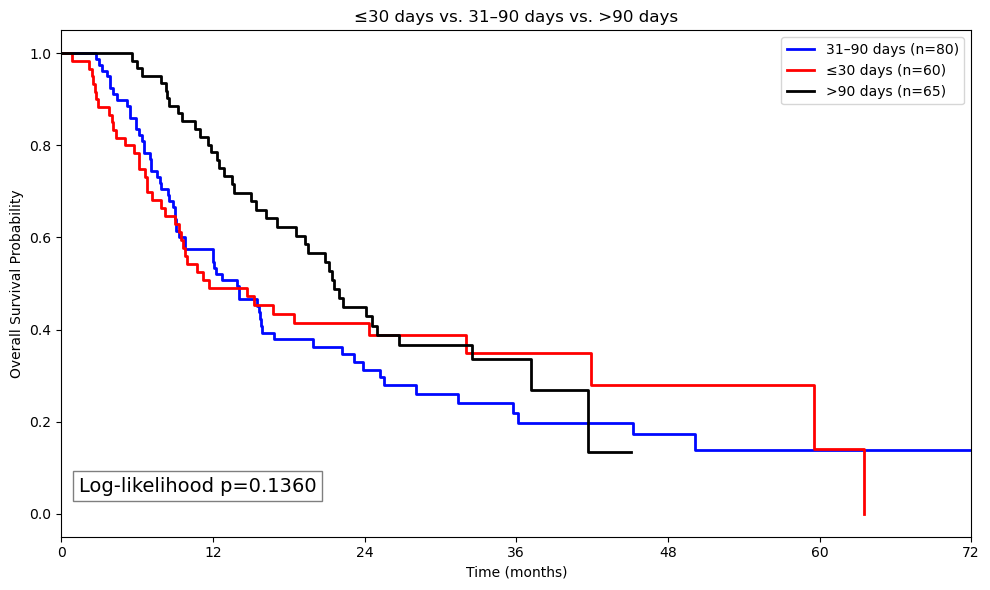

In [20]:
plot_km_by_category(df_sys, 'spacing_3090', "≤30 days vs. 31–90 days vs. >90 days", 0.136)

### Quartiles

In [21]:
df_sys['spacing_quartile'] = pd.qcut(df_sys['treatment_spacing'], q=4, labels=['≤22 days', '23–62 days', '63–105 days', '>105 days'])
quartile_cutoffs = df_sys['treatment_spacing'].quantile([0.25, 0.5, 0.75]).values
print("Quartile cutoffs:", quartile_cutoffs)

df_sys['spacing_quartile'] = pd.Categorical(
    df_sys['spacing_quartile'],
    categories=['>105 days', '≤22 days', '23–62 days', '63–105 days'],  # Reorder categories to match quartiles
    ordered=True
)

df_dummies3 = pd.get_dummies(df_sys, columns=['spacing_quartile'], drop_first=True)
cph_q = CoxPHFitter()
cph_q.fit(
    df_dummies3[['time', 'event'] + list(df_dummies3.columns[df_dummies3.columns.str.startswith('spacing_quartile_')])],
    duration_col='time',
    event_col='event'
)
cph_q.print_summary()

Quartile cutoffs: [ 28.  63. 110.]


<lifelines.CoxPHFitter: fitted with 205 total observations, 69 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 205
number of events observed = 136
   partial log-likelihood = -627.07
         time fit was run = 2026-11-01 22:28:30 UTC

---
                              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                     
spacing_quartile_≤22 days     0.22      1.24      0.25           -0.27            0.70                0.77                2.01
spacing_quartile_23–62 days   0.37      1.45      0.25           -0.11            0.85                0.89                2.35
spacing_quartile_63–105 days  0.32      1.38      0.25           -0.17            0.81                0.85                2.25

                              cmp to    z    p  -log2(p)
covariate                                               
spacing_quartile_≤22 days       0.00 0.88 0.38      1.39
spacing_quartile_23–62 days     0.00 1.50 0.13      2.91
spacing_quartile_63–105 days    0.00 1.29 0.20      2.35
---
Concordance = 0.57
Partial AIC = 1260.14
log-likelihood ratio test = 2.72 on 3 df
-log2(p) of ll-ratio test = 1.20

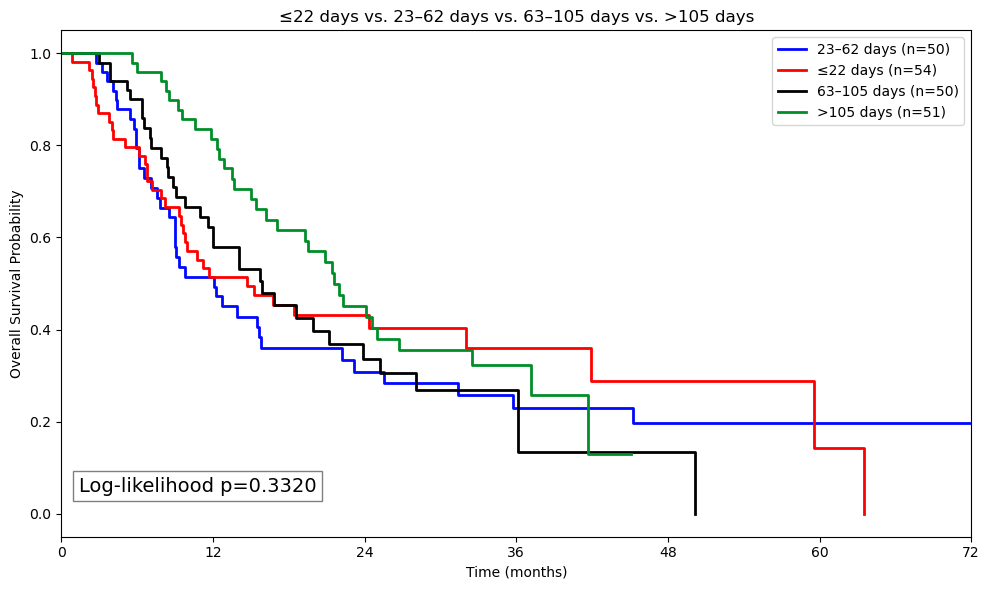

In [22]:
plot_km_by_category(df_sys, 'spacing_quartile', '≤22 days vs. 23–62 days vs. 63–105 days vs. >105 days', 0.332)

### Log rank test for best cut point

In [23]:
best_cut, best_stat = best_logrank_cutpoint(df_sys)
print("Optimal cutpoint (days):", best_cut, "– log‐rank stat:", best_stat)

best_cut = 14  # pre-specified cut point used in the paper

Optimal cutpoint (days): 88 – log‐rank stat: 4.388339942215598


In [24]:
df_sys['spacing_binary'] = (df_sys['treatment_spacing'] > best_cut).astype(int)
cph_cut = CoxPHFitter()
# cph_cut.fit(
#     df_sys[['time','event','spacing_binary']],
#     duration_col='time',
#     event_col='event'
# )
# cph_cut.print_summary()
# cph_cut.summary.loc['spacing_binary', 'p'].round(4)

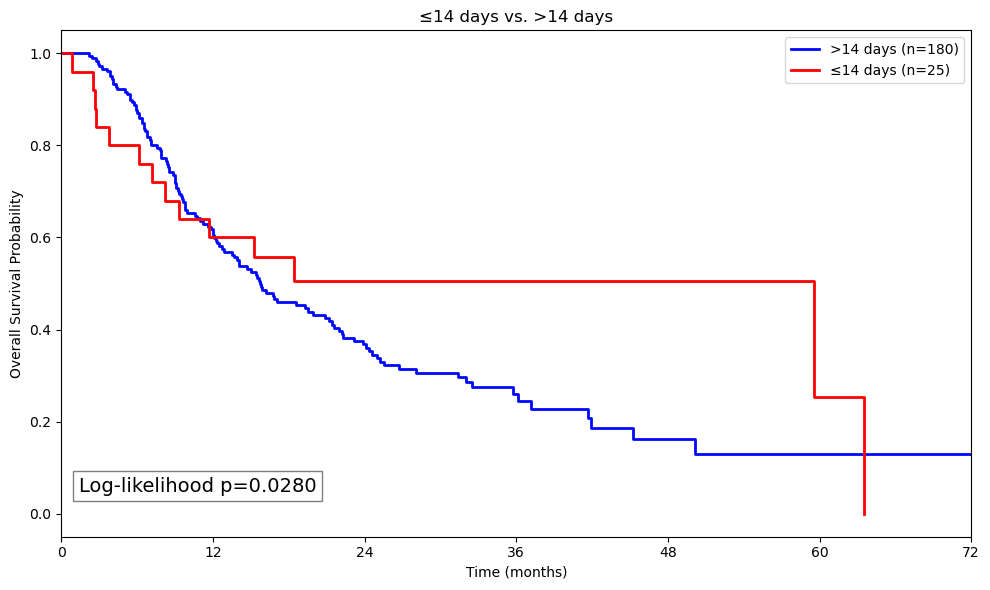

In [25]:
df_sys['spacing_binary'] = df_sys['spacing_binary'].map({0: '≤' + str(best_cut) + ' days', 1: '>' + str(best_cut) + ' days'})
plot_km_by_category(df_sys, 'spacing_binary', '≤14 days vs. >14 days', 0.028)

### Rrestricted Cubic Spline

In [26]:
from sklearn.preprocessing import SplineTransformer

median_spacing = df_sys['treatment_spacing'].median()
spacing_centered = df_sys['treatment_spacing'] - median_spacing

quantiles = np.percentile(spacing_centered, [20, 40, 60, 80])
knots = quantiles.reshape(-1, 1)

spline = SplineTransformer(
    degree=3,
    knots=knots,            
    extrapolation="linear", 
    include_bias=False      
)
X_spline = spline.fit_transform(spacing_centered.values.reshape(-1, 1))

basis_df = pd.DataFrame(
    X_spline, 
    columns=[f"spline_{i+1}" for i in range(X_spline.shape[1])]
)

for colname in basis_df.columns:
    df_sys[colname] = basis_df[colname].values

cph_rcs = CoxPHFitter()

cph_rcs.fit(
    df_sys[['time', 'event'] + basis_df.columns.tolist()],
    duration_col='time', 
    event_col='event'
)
cph_rcs.print_summary()

x_min, x_max = spacing_centered.min(), spacing_centered.max()
xs = np.linspace(x_min, x_max, 200)
xs_actual = xs + median_spacing  
X_grid = spline.transform(xs.reshape(-1, 1))  

B_ref = spline.transform([[0]])

# Extract the estimated beta coefficients for the spline columns:
beta_spline = cph_rcs.params_.loc[basis_df.columns].values

# Compute f(xs): a length-200 array
f_xs = X_grid.dot(beta_spline)

# Compute f(x_ref): a single number
f_xref = B_ref.dot(beta_spline).item()

# Now the “log–HR” relative to x_ref at each grid point:
log_hr = f_xs - f_xref

# And the HR curve:
hr_curve = np.exp(log_hr)

<lifelines.CoxPHFitter: fitted with 205 total observations, 69 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 205
number of events observed = 136
   partial log-likelihood = -624.79
         time fit was run = 2026-11-01 22:28:31 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
spline_1  -3.65      0.03      2.28           -8.12            0.81                0.00                2.26
spline_2   0.25      1.28      0.80           -1.33            1.82                0.26                6.18
spline_3  -1.05      0.35      1.24           -3.47            1.38                0.03                3.97
spline_4  -0.31      0.73      0.41           -1.11            0.49                0.33                1.63
spline_5  -1.64      0.19      1.50           -4.58            1.30                0.01                3.66

           cmp to     z    p  -log2(p)
covariate                             
spline_1     0.00 -1.60 0.11      3.20
spline_2     0.00  0.31 0.76      0.40
spline_3     0.00 -0.85 0.40      1.33
spline_4     0.00 -0.76 0.44      1.17
spline_5     0.00 -1.10 0.27      1.87
---
Concordance = 0.58
Partial AIC = 1259.58
log-likelihood ratio test = 7.28 on 5 df
-log2(p) of ll-ratio test = 2.32

In [27]:
#Bootstrapping for confidence intervals
n_boot = 200

hr_boot = np.zeros((n_boot, len(xs_actual)))  

for i in range(n_boot):
    boot_df = df_sys.sample(frac=1, replace=True, random_state=i).copy()

    median_b = boot_df['treatment_spacing'].median()

    boot_df['spacing_centered_b'] = boot_df['treatment_spacing'] - median_b

    quantile_positions = [5, 35, 65, 95]
    knot_values_b = np.percentile(
        boot_df['spacing_centered_b'], quantile_positions
    ).reshape(-1,1)

    sb_b = SplineTransformer(
        degree=3,
        knots=knot_values_b,
        extrapolation="linear",
        include_bias=False
    )

    Xb = sb_b.fit_transform(boot_df[['spacing_centered_b']].values)
    spline_cols_b = [f"spline_b_{j+1}" for j in range(Xb.shape[1])]
    for j, col in enumerate(spline_cols_b):
        boot_df[col] = Xb[:, j]

    cph_b = CoxPHFitter(penalizer=0.01)
    cph_b.fit(
        boot_df[['time', 'event'] + spline_cols_b],
        duration_col='time',
        event_col='event'
    )
    beta_b = cph_b.params_.loc[spline_cols_b].values

    xs_b_centered = xs_actual - median_b

    Xg_b = sb_b.transform(xs_b_centered.reshape(-1, 1))

    fx_b   = Xg_b.dot(beta_b)                        
    bref_b = sb_b.transform([[0]]).ravel()           
    fref_b = bref_b.dot(beta_b)

    hr_boot[i, :] = np.exp(fx_b - fref_b)

hr_lower = np.percentile(hr_boot, 2.5, axis=0)
hr_upper = np.percentile(hr_boot, 97.5, axis=0)
hr_median = np.percentile(hr_boot, 50, axis=0)

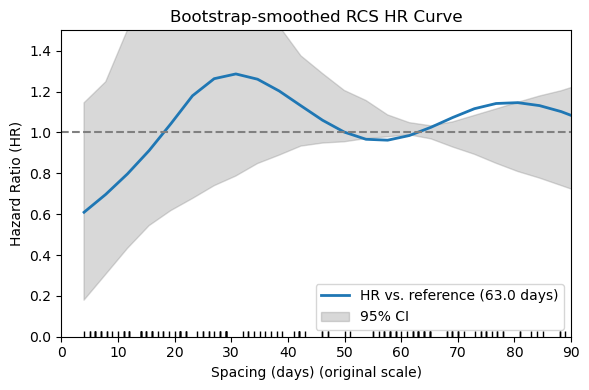

In [28]:
plt.figure(figsize=(6,4))
plt.plot(
    xs_actual,                   
    hr_curve,
    lw=2,
    label=f"HR vs. reference ({median_spacing:.1f} days)"
)
plt.fill_between(
    xs_actual, 
    hr_lower, 
    hr_upper, 
    color='gray', 
    alpha=0.3, 
    label='95% CI'
)
sns.rugplot(df_sys['treatment_spacing'], height=0.02, color="black")
plt.ylim(0, 1.5)
plt.xlim(0,90)
plt.axhline(1.0, color='gray', linestyle='--')
plt.xlabel("Spacing (days) (original scale)")
plt.ylabel("Hazard Ratio (HR)")
plt.title("Bootstrap‐smoothed RCS HR Curve")
plt.legend()
plt.tight_layout()
plt.show()

## Spacing Analysis - TACE first

<Axes: xlabel='treatment_spacing', ylabel='Count'>

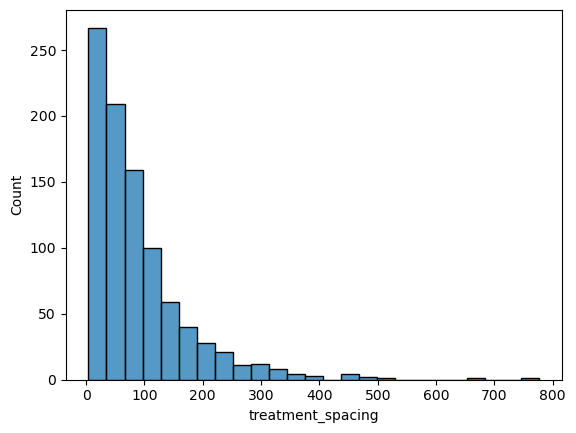

In [29]:
df_tace = df[df['sequence_group'] == 0].copy()
df_tace['treatment_spacing'] =  abs(df_tace['DX_CHEMO_STARTED_DAYS'] - df_tace['DX_IMMUNO_STARTED_DAYS'])
sns.histplot(df_tace['treatment_spacing'], bins=25)

### 7,14,28

In [30]:
df_tace['spacing_week'] = pd.cut(
    df_tace['treatment_spacing'],
    bins=[-1, 7, 14, 28, np.inf],
    labels=['≤7 days', '8–14 days', '15–28 days', '>28 days']
)

cph_7 = CoxPHFitter()
df_dummies1 = pd.get_dummies(df_tace, columns=['spacing_week'], drop_first=True)
# cph_7.fit(
#     df_dummies1[['time', 'event'] + list(df_dummies1.columns[df_dummies1.columns.str.startswith('spacing_week_')])], 
#     duration_col='time', 
#     event_col='event')
# cph_7.print_summary()
# plot_spacing(df_tace, 'spacing_week', "≤7 days vs. 8–14 days vs. 15–28 days vs. >28 days")

### 30,90

In [31]:
df_tace['spacing_3090'] = pd.cut(
    df_tace['treatment_spacing'],
    bins=[-1, 30, 90, np.inf],
    labels=['≤30 days', '31–90 days', '>90 days']
)

df_tace['spacing_3090'] = pd.Categorical(
    df_tace['spacing_3090'],
    categories=['>90 days', '31–90 days', '≤30 days'],  # Reorder categories
    ordered=True
)

cph_3090 = CoxPHFitter()
df_dummies2 = pd.get_dummies(df_tace, columns=['spacing_3090'], drop_first=True)
cph_3090.fit(
    df_dummies2[['time', 'event'] + list(df_dummies2.columns[df_dummies2.columns.str.startswith('spacing_3090_')])], 
    duration_col='time', 
    event_col='event')
cph_3090.print_summary()

# plot_spacing(df_tace, 'spacing_3090', "≤30 days vs. 31–90 days vs. >90 days")

<lifelines.CoxPHFitter: fitted with 930 total observations, 216 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 930
number of events observed = 714
   partial log-likelihood = -4375.70
         time fit was run = 2026-11-01 22:28:34 UTC

---
                         coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                
spacing_3090_31–90 days  0.30      1.34      0.09            0.13            0.47                1.13                1.59
spacing_3090_≤30 days    0.26      1.30      0.10            0.07            0.45                1.07                1.57

                         cmp to    z      p  -log2(p)
covariate                                            
spacing_3090_31–90 days    0.00 3.40 <0.005     10.55
spacing_3090_≤30 days      0.00 2.68   0.01      7.07
---
Concordance = 0.56
Partial AIC = 8755.39
log-likelihood ratio test = 13.37 on 2 df
-log2(p) of ll-ratio test = 9.65

### Quartiles

In [32]:
df_tace['spacing_quartile'] = pd.qcut(df_tace['treatment_spacing'], q=4, labels=['≤31 days', '32–67 days', '68–125 days', '>125 days'])
quartile_cutoffs = df_tace['treatment_spacing'].quantile([0.25, 0.5, 0.75]).values
print("Quartile cutoffs:", quartile_cutoffs)

df_tace['spacing_quartile'] = pd.Categorical(
    df_tace['spacing_quartile'],
    categories=['>125 days', '≤31 days', '32–67 days', '68–125 days'],  # Reorder categories to match quartiles
    ordered=True
)

df_dummies3 = pd.get_dummies(df_tace, columns=['spacing_quartile'], drop_first=True)
cph_q = CoxPHFitter()
cph_q.fit(
    df_dummies3[['time', 'event'] + list(df_dummies3.columns[df_dummies3.columns.str.startswith('spacing_quartile_')])],
    duration_col='time',
    event_col='event'
)
cph_q.print_summary()

# plot_spacing(df_tace, 'spacing_quartile', '≤31 days vs. 32–67 days vs. 68–125 days vs. >125 days')

Quartile cutoffs: [ 30.    63.   113.75]


<lifelines.CoxPHFitter: fitted with 930 total observations, 216 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 930
number of events observed = 714
   partial log-likelihood = -4372.03
         time fit was run = 2026-11-01 22:28:35 UTC

---
                              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                     
spacing_quartile_≤31 days     0.34      1.40      0.11            0.13            0.55                1.14                1.73
spacing_quartile_32–67 days   0.46      1.59      0.11            0.25            0.67                1.29                1.95
spacing_quartile_68–125 days  0.25      1.28      0.11            0.04            0.46                1.04                1.58

                              cmp to    z      p  -log2(p)
covariate                                                 
spacing_quartile_≤31 days       0.00 3.18 <0.005      9.42
spacing_quartile_32–67 days     0.00 4.34 <0.005     16.12
spacing_quartile_68–125 days    0.00 2.34   0.02      5.70
---
Concordance = 0.59
Partial AIC = 8750.05
log-likelihood ratio test = 20.71 on 3 df
-log2(p) of ll-ratio test = 13.02

### Log rank for best cut

In [33]:
best_cut, best_stat = best_logrank_cutpoint(df_tace)

print("Optimal cutpoint (days):", best_cut, "– log‐rank stat:", best_stat)

df_tace['spacing_binary'] = (df_tace['treatment_spacing'] > best_cut).astype(int)
cph_cut = CoxPHFitter()
cph_cut.fit(
    df_tace[['time','event','spacing_binary']],
    duration_col='time',
    event_col='event'
)
cph_cut.print_summary()
cph_cut.summary.loc['spacing_binary', 'p'].round(4)

# plot_spacing(df_tace, 'spacing_binary', '≤105 days vs. >105 days')

Optimal cutpoint (days): 97 – log‐rank stat: 18.55966366901092


<lifelines.CoxPHFitter: fitted with 930 total observations, 216 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 930
number of events observed = 714
   partial log-likelihood = -4372.80
         time fit was run = 2026-11-01 22:28:35 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
spacing_binary -0.35      0.70      0.08           -0.51           -0.19                0.60                0.83

                cmp to     z      p  -log2(p)
covariate                                    
spacing_binary    0.00 -4.29 <0.005     15.75
---
Concordance = 0.57
Partial AIC = 8747.60
log-likelihood ratio test = 19.16 on 1 df
-log2(p) of ll-ratio test = 16.35

np.float64(0.0)

### TACE RCS

<lifelines.CoxPHFitter: fitted with 930 total observations, 216 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 930
number of events observed = 714
   partial log-likelihood = -4369.96
         time fit was run = 2026-11-01 22:28:35 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
spline_1   1.82      6.20      1.35           -0.83            4.47                0.44               87.77
spline_2   0.38      1.46      0.65           -0.90            1.65                0.41                5.22
spline_3   0.73      2.08      0.78           -0.80            2.26                0.45                9.57
spline_4   0.31      1.36      0.53           -0.73            1.35                0.48                3.85
spline_5   0.10      1.11      1.08           -2.01            2.22                0.13                9.19

           cmp to    z    p  -log2(p)
covariate                            
spline_1     0.00 1.35 0.18      2.49
spline_2     0.00 0.58 0.56      0.82
spline_3     0.00 0.94 0.35      1.52
spline_4     0.00 0.59 0.56      0.84
spline_5     0.00 0.10 0.92      0.12
---
Concordance = 0.59
Partial AIC = 8749.93
log-likelihood ratio test = 24.84 on 5 df
-log2(p) of ll-ratio test = 12.71

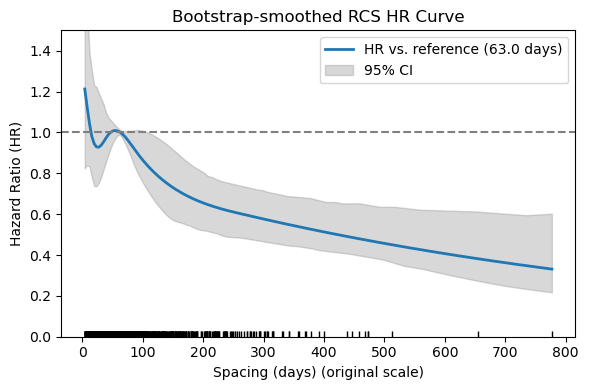

In [34]:
median_spacing = df_tace['treatment_spacing'].median()
spacing_centered = df_tace['treatment_spacing'] - median_spacing

quantiles = np.percentile(spacing_centered, [5, 35, 65, 95])
knots = quantiles.reshape(-1, 1)

spline = SplineTransformer(
    degree=3,
    knots=knots,            
    extrapolation="linear", 
    include_bias=False      
)
X_spline = spline.fit_transform(spacing_centered.values.reshape(-1, 1))

basis_df = pd.DataFrame(
    X_spline, 
    columns=[f"spline_{i+1}" for i in range(X_spline.shape[1])]
)

for colname in basis_df.columns:
    df_tace[colname] = basis_df[colname].values

cph_rcs = CoxPHFitter()

cph_rcs.fit(
    df_tace[['time', 'event'] + basis_df.columns.tolist()],
    duration_col='time', 
    event_col='event'
)
cph_rcs.print_summary()

x_min, x_max = spacing_centered.min(), spacing_centered.max()
xs = np.linspace(x_min, x_max, 200)
xs_actual = xs + median_spacing  
X_grid = spline.transform(xs.reshape(-1, 1))  

B_ref = spline.transform([[0]])

# Extract the estimated beta coefficients for the spline columns:
beta_spline = cph_rcs.params_.loc[basis_df.columns].values

# Compute f(xs): a length-200 array
f_xs = X_grid.dot(beta_spline)

# Compute f(x_ref): a single number
f_xref = B_ref.dot(beta_spline).item()

# Now the “log–HR” relative to x_ref at each grid point:
log_hr = f_xs - f_xref

# And the HR curve:
hr_curve = np.exp(log_hr)

#Bootstrapping for confidence intervals
n_boot = 200

hr_boot = np.zeros((n_boot, len(xs_actual)))  

for i in range(n_boot):
    boot_df = df_tace.sample(frac=1, replace=True, random_state=i).copy()

    median_b = boot_df['treatment_spacing'].median()

    boot_df['spacing_centered_b'] = boot_df['treatment_spacing'] - median_b

    quantile_positions = [5, 35, 65, 95]
    knot_values_b = np.percentile(
        boot_df['spacing_centered_b'], quantile_positions
    ).reshape(-1,1)

    sb_b = SplineTransformer(
        degree=3,
        knots=knot_values_b,
        extrapolation="linear",
        include_bias=False
    )

    Xb = sb_b.fit_transform(boot_df[['spacing_centered_b']].values)
    spline_cols_b = [f"spline_b_{j+1}" for j in range(Xb.shape[1])]
    for j, col in enumerate(spline_cols_b):
        boot_df[col] = Xb[:, j]

    cph_b = CoxPHFitter(penalizer=0.01)
    cph_b.fit(
        boot_df[['time', 'event'] + spline_cols_b],
        duration_col='time',
        event_col='event'
    )
    beta_b = cph_b.params_.loc[spline_cols_b].values

    xs_b_centered = xs_actual - median_b

    Xg_b = sb_b.transform(xs_b_centered.reshape(-1, 1))

    fx_b   = Xg_b.dot(beta_b)                        
    bref_b = sb_b.transform([[0]]).ravel()           
    fref_b = bref_b.dot(beta_b)

    hr_boot[i, :] = np.exp(fx_b - fref_b)

hr_lower = np.percentile(hr_boot, 2.5, axis=0)
hr_upper = np.percentile(hr_boot, 97.5, axis=0)
hr_median = np.percentile(hr_boot, 50, axis=0)

plt.figure(figsize=(6,4))
plt.plot(
    xs_actual,                   
    hr_curve,
    lw=2,
    label=f"HR vs. reference ({median_spacing:.1f} days)"
)
plt.fill_between(
    xs_actual, 
    hr_lower, 
    hr_upper, 
    color='gray', 
    alpha=0.3, 
    label='95% CI'
)
sns.rugplot(df_tace['treatment_spacing'], height=0.02, color="black")
plt.ylim(0, 1.5)
plt.axhline(1.0, color='gray', linestyle='--')
plt.xlabel("Spacing (days) (original scale)")
plt.ylabel("Hazard Ratio (HR)")
plt.title("Bootstrap‐smoothed RCS HR Curve")
plt.legend()
plt.tight_layout()
plt.show()

## TACE first vs. Systemic First across different spacing

<Axes: xlabel='treatment_spacing', ylabel='Count'>

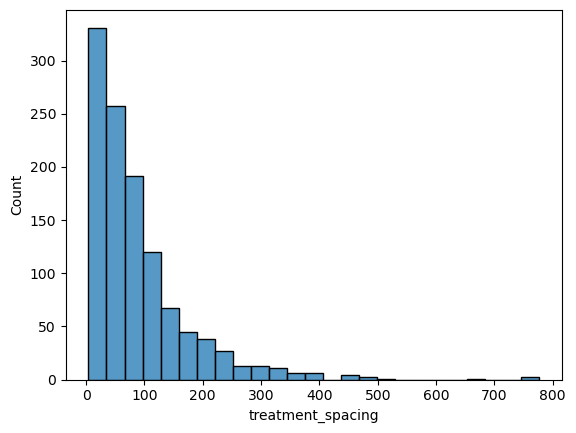

In [35]:
df['treatment_spacing'] =  abs(df['DX_CHEMO_STARTED_DAYS'] - df['DX_IMMUNO_STARTED_DAYS'])
sns.histplot(df['treatment_spacing'], bins=25)

In [36]:
best_cut_all, best_stat_all = best_logrank_cutpoint(df)
print("Optimal cutpoint (days):", best_cut_all, "– log‐rank stat:", best_stat_all)

Optimal cutpoint (days): 95 – log‐rank stat: 20.86838792579934


In [37]:
spacings = ['spacing_binary', 'spacing_quartile', 'spacing_3090', 'spacing_week']

df['spacing_quartile'] = pd.qcut(df['treatment_spacing'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
df['spacing_3090'] = pd.cut(
    df['treatment_spacing'],
    bins=[-1, 30, 90, np.inf],
    labels=['≤30 days', '31–90 days', '>90 days']
)
df['spacing_week'] = pd.cut(
    df['treatment_spacing'],
    bins=[-1, 7, 14, 28, np.inf],
    labels=['≤7 days', '8–14 days', '15–28 days', '>28 days']
)
df['spacing_binary'] = (df['treatment_spacing'] > best_cut_all).astype(int).map({0: '≤' + str(best_cut_all) + ' days', 1: '>' + str(best_cut_all) + ' days'})


df_results2 = pd.DataFrame(columns=['Spacing Group', 'HR', 'CI Low', 'CI High', 'p-value', 'n'])

for spacing in spacings:
    for group in df[spacing].unique():
        group_mask = df[spacing] == group
        df_group = df[group_mask].copy()
        df_group = perform_iptw(df_group)

        cph = CoxPHFitter()
        cph.fit(
            df_group[['time', 'event', 'sequence_group', 'iptw_weight']],
            duration_col='time',
            event_col='event',
            weights_col='iptw_weight'
        )
        summary_df = cph.summary
        p_val = summary_df.loc['sequence_group', 'p'].round(4)
        hr = summary_df.loc['sequence_group', 'exp(coef)']
        ci_low = summary_df.loc['sequence_group', 'exp(coef) lower 95%']
        ci_high = summary_df.loc['sequence_group', 'exp(coef) upper 95%']
        n = df_group.shape[0]
        new_row = pd.DataFrame({
            'Spacing Group': [f"{spacing} - {group}"],
            'HR': [hr],
            'CI Low': [ci_low],
            'CI High': [ci_high],
            'p-value': [p_val],
            'n': [n]
        })
        df_results2 = pd.concat([df_results2, new_row], ignore_index=True)
    
    new_row = pd.DataFrame([{
        'Spacing Group': "",
        'HR': "",
        'CI Low': "",
        'CI High': "",
        'p-value': "",
        'n': ""
    }])
    df_results2 = pd.concat([df_results2, new_row], ignore_index=True)
        

df_results2

,Spacing Group,HR,CI Low,CI High,p-value,n
0,spacing_binary - >95 days,0.951097,0.797054,1.134911,0.5781,362
1,spacing_binary - ≤95 days,0.808895,0.719468,0.909437,0.0004,773
2,,,,,,
3,spacing_quartile - Q3,1.155211,0.949499,1.405491,0.1493,283
4,spacing_quartile - Q4,0.870766,0.7133,1.062993,0.1739,282
5,spacing_quartile - Q1,0.844513,0.695162,1.025951,0.0888,292
6,spacing_quartile - Q2,0.698804,0.572594,0.852833,0.0004,278
7,,,,,,
8,spacing_3090 - >90 days,0.912197,0.769303,1.081632,0.2904,393
9,spacing_3090 - ≤30 days,0.83633,0.689764,1.01404,0.069,298
